# Fine-tuning T5 for Abstractive Summarisation (CNN/DailyMail)
**Task:** summarisation

**Data:** `abisee/cnn_dailymail` from Hugging Face

**Model:** T5 family, fine-tuned

**Metric:** ROUGE-1/2/L/Lsum

Pipeline: load data → NLP cleaning → tokenise → fine-tune → evaluate on test set → expected-vs-generated samples → inference.

## 1. Install

In [19]:
!pip install -q -U transformers datasets accelerate sentencepiece rouge_score pandas


## 2. Configuration
Set `N_TRAIN = None` for the full 287k training set. Use `google/flan-t5-base` for higher scores (needs a GPU).

In [20]:
MODEL_NAME = "t5-small"          # or "google/flan-t5-base"
DATASET, DATASET_CONFIG = "abisee/cnn_dailymail", "3.0.0"
N_TRAIN, N_VAL, N_TEST = 20000, 1000, 1000   # None = use the full split
EPOCHS, LR = 3, 3e-4
TRAIN_BS, EVAL_BS, GRAD_ACCUM = 8, 16, 4
MAX_SOURCE, MAX_TARGET, NUM_BEAMS = 512, 128, 4
PREFIX = "summarize: "
OUT_DIR, SEED = "outputs", 42


## 3. Imports

In [21]:
import hashlib, html, json, os, re, unicodedata
import numpy as np, pandas as pd, torch
from datasets import load_dataset
from rouge_score import rouge_scorer
from transformers import (AutoModelForSeq2SeqLM, AutoTokenizer, DataCollatorForSeq2Seq,
                          Seq2SeqTrainer, Seq2SeqTrainingArguments, set_seed)
set_seed(SEED)
os.makedirs(OUT_DIR, exist_ok=True)
print("device:", "cuda" if torch.cuda.is_available() else "cpu")


device: cuda


## 4. NLP cleaning functions
Unicode/HTML normalisation, URL/e-mail/@handle removal, datelines (`LONDON, England (CNN) --`), bylines, boilerplate, whitespace/punctuation repair; then length/ratio filters, de-duplication and copy-summary removal.

In [22]:
import hashlib
import html
import re
import unicodedata

# --- regexes -----------------------------------------------------------------
_TAG = re.compile(r"<[^>]+>")
_URL = re.compile(r"(https?://\S+|www\.\S+)", re.I)
_EMAIL = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b")
_HANDLE = re.compile(r"(?<!\w)@\w{2,}")
# Agency / dateline prefixes: "LONDON, England (CNN) -- ", "(CNN) -- ", "By . Daily Mail Reporter ."
_DATELINE = re.compile(
    r"^\s*(?:[A-Z][A-Za-z.\s,'-]{0,60}?)?\(\s*(?:CNN|Reuters|AP|AFP|EW\.com|CNN\.com)\s*\)\s*(?:--|-|—|:)?\s*",
)
_BYLINE = re.compile(r"^\s*By\s+\.?\s*[A-Z][\w.\s,'-]{0,60}?\s+\.\s*", re.I)
_PUBLISHED = re.compile(
    r"(?:UPDATED|PUBLISHED|Last updated at)\s*:?\s*\.?\s*[\d:.\s]*(?:AM|PM|EST|GMT|BST|EDT)?[^.]{0,40}?\d{4}\s*\.?",
    re.I,
)
_BOILER = re.compile(
    r"(?:Scroll down for video|Click here to[^.]*\.|Read more:|See more:?|Share this article|"
    r"Share or comment on this article|Follow @\w+|E-mail to a friend|Copyright \d{4}[^.]*\.|"
    r"All rights reserved\.?|Print\s+Email\s+Share|NEW:|EXCLUSIVE:|MORE:)",
    re.I,
)
_WS = re.compile(r"\s+")
_SPACE_PUNCT = re.compile(r"\s+([,.;:!?%)\]])")
_MULTI_PUNCT = re.compile(r"([.!?]){2,}")
_NONPRINT = re.compile(r"""[\u0000-\u0008\u000b\u000c\u000e-\u001f\u007f​\-‏
\- ﻿]""")

_QUOTES = {"‘": "'", "’": "'", "“": '"', "”": '"', "–": "-", "—": " - ", "…": "..."}


def normalize_text(text: str) -> str:
    """Unicode, HTML entities, control chars, quotes."""
    if text is None:
        return ""
    text = html.unescape(str(text))
    text = unicodedata.normalize("NFKC", text)
    for k, v in _QUOTES.items():
        text = text.replace(k, v)
    return _NONPRINT.sub(" ", text)


def clean_article(text: str) -> str:
    text = normalize_text(text)
    text = _TAG.sub(" ", text)
    text = _URL.sub(" ", text)
    text = _EMAIL.sub(" ", text)
    text = _HANDLE.sub(" ", text)
    text = _PUBLISHED.sub(" ", text)
    text = _BOILER.sub(" ", text)
    # strip dateline / byline repeatedly (some articles stack them)
    for _ in range(3):
        new = _DATELINE.sub("", text, count=1)
        new = _BYLINE.sub("", new, count=1)
        if new == text:
            break
        text = new
    text = _WS.sub(" ", text)
    text = _SPACE_PUNCT.sub(r"\1", text)
    text = _MULTI_PUNCT.sub(r"\1", text)
    return text.strip()


def clean_summary(text: str) -> str:
    """Highlights come newline separated; make them proper sentences."""
    text = normalize_text(text)
    text = _TAG.sub(" ", text)
    text = _URL.sub(" ", text)
    parts = [p.strip() for p in re.split(r"\n+", text) if p.strip()]
    fixed = []
    for p in parts:
        p = _BOILER.sub(" ", p)
        p = _WS.sub(" ", p).strip()
        p = _SPACE_PUNCT.sub(r"\1", p)
        if not p:
            continue
        if p[-1] not in ".!?\"'":
            p += "."
        fixed.append(p[0].upper() + p[1:])
    return " ".join(fixed)


def _wc(s: str) -> int:
    return len(s.split())


def clean_dataset(ds, text_col="article", sum_col="highlights",
                  min_article_words=50, max_article_words=3000,
                  min_summary_words=10, max_summary_words=150,
                  min_ratio=0.03, max_ratio=0.8, num_proc=1):
    """Clean + filter a HF Dataset split. Returns (dataset, stats)."""
    stats = {"input_rows": len(ds)}

    def _clean(batch):
        return {
            text_col: [clean_article(x) for x in batch[text_col]],
            sum_col: [clean_summary(x) for x in batch[sum_col]],
        }

    ds = ds.map(_clean, batched=True, num_proc=num_proc, desc="cleaning text")

    # length / ratio filters
    def _keep(ex):
        a, s = _wc(ex[text_col]), _wc(ex[sum_col])
        if a < min_article_words or a > max_article_words:
            return False
        if s < min_summary_words or s > max_summary_words:
            return False
        r = s / a
        return min_ratio <= r <= max_ratio

    before = len(ds)
    ds = ds.filter(_keep, desc="length filters")
    stats["removed_length_or_ratio"] = before - len(ds)

    # exact-duplicate removal on article text
    seen, keep_idx = set(), []
    for i, a in enumerate(ds[text_col]):
        h = hashlib.md5(a.encode("utf-8")).hexdigest()
        if h in seen:
            continue
        seen.add(h)
        keep_idx.append(i)
    stats["removed_duplicates"] = len(ds) - len(keep_idx)
    ds = ds.select(keep_idx)

    # summary must not be a verbatim copy of the whole article
    before = len(ds)
    ds = ds.filter(lambda ex: ex[sum_col] not in ex[text_col] or _wc(ex[sum_col]) < 0.5 * _wc(ex[text_col]))
    stats["removed_copy_summaries"] = before - len(ds)

    stats["output_rows"] = len(ds)
    return ds, stats

## 5. ROUGE metrics (fully offline, no hub download)

In [23]:
import re
import numpy as np
from rouge_score import rouge_scorer

_scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL", "rougeLsum"], use_stemmer=True)
_SENT = re.compile(r"(?<=[.!?])\s+")


def _nl(text: str) -> str:
    """rougeLsum expects one sentence per line."""
    return "\n".join(s for s in _SENT.split(text.strip()) if s)


def compute_rouge(predictions, references):
    agg = {"rouge1": [], "rouge2": [], "rougeL": [], "rougeLsum": []}
    for p, r in zip(predictions, references):
        sc = _scorer.score(_nl(r), _nl(p))
        for k in agg:
            agg[k].append(sc[k].fmeasure)
    return {k: round(100 * float(np.mean(v)), 2) for k, v in agg.items()}


def build_compute_metrics(tokenizer):
    def _fn(eval_pred):
        preds, labels = eval_pred
        if isinstance(preds, tuple):
            preds = preds[0]
        preds = np.where(preds != -100, preds, tokenizer.pad_token_id)
        labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
        dp = [t.strip() for t in tokenizer.batch_decode(preds, skip_special_tokens=True)]
        dl = [t.strip() for t in tokenizer.batch_decode(labels, skip_special_tokens=True)]
        out = compute_rouge(dp, dl)
        out["gen_len"] = round(float(np.mean([len(p.split()) for p in dp])), 2)
        return out
    return _fn


## 6. Training and generation helpers

In [24]:
import json
import os

import numpy as np
import torch
from transformers import (DataCollatorForSeq2Seq, Seq2SeqTrainer, Seq2SeqTrainingArguments)



def make_training_args(output_dir, epochs=3, lr=3e-4, train_bs=8, eval_bs=16, grad_accum=4,
                       warmup_ratio=0.05, weight_decay=0.01, max_target=128, num_beams=4,
                       seed=42, max_steps=-1, logging_steps=50, eval_steps=None):
    cuda = torch.cuda.is_available()
    bf16 = cuda and torch.cuda.is_bf16_supported()   # T5 + fp16 is unstable, so bf16 or fp32 only
    kw = dict(
        output_dir=output_dir,
        num_train_epochs=epochs,
        max_steps=max_steps,
        learning_rate=lr,
        per_device_train_batch_size=train_bs,
        per_device_eval_batch_size=eval_bs,
        gradient_accumulation_steps=grad_accum,
        warmup_steps=0,
        weight_decay=weight_decay,
        lr_scheduler_type="linear",
        eval_strategy="steps" if eval_steps else "epoch",
        save_strategy="steps" if eval_steps else "epoch",
        save_total_limit=2,
        load_best_model_at_end=True,
        metric_for_best_model="rougeLsum",
        greater_is_better=True,
        predict_with_generate=True,
        generation_max_length=max_target,
        generation_num_beams=num_beams,
        logging_steps=logging_steps,
        bf16=bf16,
        seed=seed,
        report_to="none",
        dataloader_num_workers=0,
    )
    if eval_steps:
        kw["eval_steps"] = eval_steps
        kw["save_steps"] = eval_steps
    return Seq2SeqTrainingArguments(**kw)


def train(model, tokenizer, tokenized, args):
    collator = DataCollatorForSeq2Seq(tokenizer, model=model, label_pad_token_id=-100, pad_to_multiple_of=8)
    common = dict(model=model, args=args, train_dataset=tokenized["train"],
                  eval_dataset=tokenized["validation"], data_collator=collator,
                  compute_metrics=build_compute_metrics(tokenizer))
    try:
        trainer = Seq2SeqTrainer(processing_class=tokenizer, **common)   # transformers >= 4.46
    except TypeError:
        trainer = Seq2SeqTrainer(tokenizer=tokenizer, **common)          # older versions
    result = trainer.train()
    trainer.save_model(args.output_dir + "/final")
    tokenizer.save_pretrained(args.output_dir + "/final")
    return trainer, result


@torch.no_grad()
def generate_summaries(model, tokenizer, texts, prefix="summarize: ", max_source=512, max_target=128,
                       num_beams=4, batch_size=16, length_penalty=2.0, no_repeat_ngram_size=3):
    device = next(model.parameters()).device
    model.eval()
    outs = []
    for i in range(0, len(texts), batch_size):
        batch = [prefix + t for t in texts[i:i + batch_size]]
        enc = tokenizer(batch, max_length=max_source, truncation=True, padding=True, return_tensors="pt").to(device)
        ids = model.generate(**enc, max_length=max_target, num_beams=num_beams,
                             length_penalty=length_penalty, no_repeat_ngram_size=no_repeat_ngram_size,
                             early_stopping=True)
        outs += [s.strip() for s in tokenizer.batch_decode(ids, skip_special_tokens=True)]
    return outs


def evaluate_test(model, tokenizer, test_clean, out_dir, text_col="article", sum_col="highlights",
                  n_examples=5, **gen_kw):
    articles, refs = list(test_clean[text_col]), list(test_clean[sum_col])
    preds = generate_summaries(model, tokenizer, articles, **gen_kw)
    scores = compute_rouge(preds, refs)
    scores["gen_len"] = round(float(np.mean([len(p.split()) for p in preds])), 2)
    scores["ref_len"] = round(float(np.mean([len(r.split()) for r in refs])), 2)
    scores["n_test"] = len(preds)
    os.makedirs(out_dir, exist_ok=True)
    with open(os.path.join(out_dir, "test_metrics.json"), "w") as f:
        json.dump(scores, f, indent=2)
    import pandas as pd
    pd.DataFrame({"article": articles, "reference": refs, "prediction": preds}).to_csv(
        os.path.join(out_dir, "test_predictions.csv"), index=False)
    # human-readable expected-vs-actual output
    with open(os.path.join(out_dir, "sample_outputs.txt"), "w") as f:
        for i in range(min(n_examples, len(preds))):
            f.write(f"=== Example {i + 1} ===\nARTICLE (first 400 chars):\n{articles[i][:400]}...\n\n")
            f.write(f"EXPECTED (reference):\n{refs[i]}\n\nGENERATED:\n{preds[i]}\n\n")
    return scores, preds


## 7. Load the dataset from Hugging Face

In [25]:
ds = load_dataset(DATASET, DATASET_CONFIG)
def take(split, n):
    d = ds[split].shuffle(seed=SEED)
    return d.select(range(min(n, len(d)))) if n else d
raw = {"train": take("train", N_TRAIN), "validation": take("validation", N_VAL), "test": take("test", N_TEST)}
print({k: len(v) for k, v in raw.items()})
print("\nRAW ARTICLE (first 500 chars):\n", raw["train"][0]["article"][:500])


{'train': 20000, 'validation': 1000, 'test': 1000}

RAW ARTICLE (first 500 chars):
 By . Anthony Bond . PUBLISHED: . 07:03 EST, 2 March 2013 . | . UPDATED: . 08:07 EST, 2 March 2013 . Three members of the same family who died in a static caravan from carbon monoxide poisoning would have been unconscious 'within minutes', investigators said today. The bodies of married couple John and Audrey Cook were discovered alongside their daughter, Maureen, at the mobile home they shared on Tremarle Home Park in Camborne, west Cornwall. The inquests have now opened into the deaths last Sat


## 8. Clean the data and inspect the result

In [26]:
cleaned, report = {}, {}
for name, d in raw.items():
    cleaned[name], report[name] = clean_dataset(d)
with open(f"{OUT_DIR}/cleaning_report.json", "w") as f:
    json.dump(report, f, indent=2)
print(json.dumps(report, indent=2))

if len(cleaned["train"]) > 0:
    print("\nCLEANED ARTICLE (first 500 chars):\n", cleaned["train"][0]["article"][:500])
    print("\nCLEANED SUMMARY:\n", cleaned["train"][0]["highlights"])
else:
    print("\nWARNING: The cleaned dataset is empty! Check your `clean_dataset` filters or `_NONPRINT` regex in cell 200bdf8d as they are removing all rows.")

cleaning text (num_proc=1):   0%|          | 0/20000 [00:00<?, ? examples/s]

length filters:   0%|          | 0/20000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/19026 [00:00<?, ? examples/s]

cleaning text (num_proc=1):   0%|          | 0/1000 [00:00<?, ? examples/s]

length filters:   0%|          | 0/1000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/964 [00:00<?, ? examples/s]

cleaning text (num_proc=1):   0%|          | 0/1000 [00:00<?, ? examples/s]

length filters:   0%|          | 0/1000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/969 [00:00<?, ? examples/s]

{
  "train": {
    "input_rows": 20000,
    "removed_length_or_ratio": 957,
    "removed_duplicates": 17,
    "removed_copy_summaries": 0,
    "output_rows": 19026
  },
  "validation": {
    "input_rows": 1000,
    "removed_length_or_ratio": 36,
    "removed_duplicates": 0,
    "removed_copy_summaries": 0,
    "output_rows": 964
  },
  "test": {
    "input_rows": 1000,
    "removed_length_or_ratio": 31,
    "removed_duplicates": 0,
    "removed_copy_summaries": 0,
    "output_rows": 969
  }
}

CLEANED ARTICLE (first 500 chars):
 |. Three members of the same family who died in a static caravan from carbon monoxide poisoning would have been unconscious 'within minutes', investigators said today. The bodies of married couple John and Audrey Cook were discovered alongside their daughter, Maureen, at the mobile home they shared on Tremarle Home Park in Camborne, west Cornwall. The inquests have now opened into the deaths last Saturday, with investigators saying the three died along with the

## 9. Tokenise

In [27]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
def _tok(batch):
    enc = tokenizer([PREFIX + t for t in batch["article"]], max_length=MAX_SOURCE, truncation=True)
    enc["labels"] = tokenizer(text_target=batch["highlights"], max_length=MAX_TARGET, truncation=True)["input_ids"]
    return enc
tokenized = {k: v.map(_tok, batched=True, remove_columns=v.column_names, desc=f"tokenising {k}")
             for k, v in cleaned.items()}
print(tokenized)


tokenising train:   0%|          | 0/19026 [00:00<?, ? examples/s]

tokenising validation:   0%|          | 0/964 [00:00<?, ? examples/s]

tokenising test:   0%|          | 0/969 [00:00<?, ? examples/s]

{'train': Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 19026
}), 'validation': Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 964
}), 'test': Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 969
})}


## 10. Fine-tune

In [28]:
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
args = make_training_args(f"{OUT_DIR}/checkpoints", EPOCHS, LR, TRAIN_BS, EVAL_BS, GRAD_ACCUM,
                          max_target=MAX_TARGET, num_beams=NUM_BEAMS, seed=SEED)
trainer, result = train(model, tokenizer, tokenized, args)
print(result.metrics)


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum,Gen Len
1,8.615828,1.858972,42.420000,20.140000,29.640000,39.420000,60.040000
2,8.514882,1.850122,42.840000,20.400000,29.940000,39.790000,61.950000
3,8.166367,1.846299,43.190000,20.640000,30.150000,40.100000,61.380000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight', 'lm_head.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': 4122.6114, 'train_samples_per_second': 13.845, 'train_steps_per_second': 0.433, 'total_flos': 7725039344418816.0, 'train_loss': 8.462562642244398, 'epoch': 3.0}


## 11. Evaluate on the test set
Writes `test_metrics.json`, `test_predictions.csv` and `sample_outputs.txt` (expected vs generated).

In [29]:
scores, preds = evaluate_test(trainer.model, tokenizer, cleaned["test"], OUT_DIR,
                              max_source=MAX_SOURCE, max_target=MAX_TARGET,
                              num_beams=NUM_BEAMS, batch_size=EVAL_BS)
print("TEST ROUGE:", json.dumps(scores, indent=2))
print(open(f"{OUT_DIR}/sample_outputs.txt").read())


TEST ROUGE: {
  "rouge1": 41.66,
  "rouge2": 19.04,
  "rougeL": 29.03,
  "rougeLsum": 38.52,
  "gen_len": 56.23,
  "ref_len": 52.69,
  "n_test": 969
}
=== Example 1 ===
ARTICLE (first 400 chars):
He looks barely teenage. But this child has amassed thousands of Twitter followers with his pictorial updates of 'gang life'. The baby faced boy from Memphis, Tennessee, poses with guns, cash, and bags of what looks like marijuana. Baby faced: This little boy has amassed more than 3,000 followers on Twitter with pictures like these. In many pictures he is smoking suspicious substances, with captio...

EXPECTED (reference):
Child has amassed thousands of Twitter followers with 'gang life' photos. In one video he points gun at camera as adults look on unfazed. His tweets have prompted backlash with calls for intervention.

GENERATED:
Baby faced boy from Memphis, Tennessee, poses with guns, cash, and bags of what looks like marijuana. In many pictures he is smoking suspicious substances, with cap

## 12. Training curve

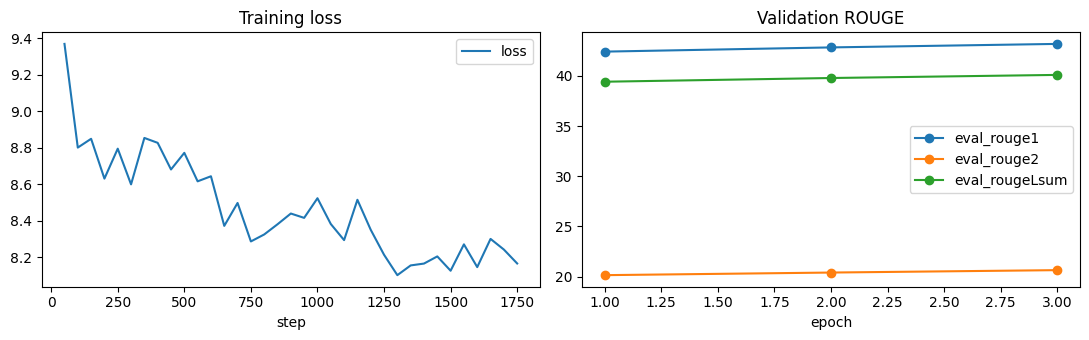

In [30]:
import matplotlib.pyplot as plt
log = pd.DataFrame(trainer.state.log_history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
if "loss" in log: log.dropna(subset=["loss"]).plot(x="step", y="loss", ax=ax[0], title="Training loss")
if "eval_rougeLsum" in log: log.dropna(subset=["eval_rougeLsum"]).plot(x="epoch", y=["eval_rouge1", "eval_rouge2", "eval_rougeLsum"], ax=ax[1], marker="o", title="Validation ROUGE")
plt.tight_layout(); plt.show()


## 13. Summarise own text

In [31]:
def summarize(text, num_beams=NUM_BEAMS):
    return generate_summaries(trainer.model, tokenizer, [clean_article(text)], max_source=MAX_SOURCE,
                              max_target=MAX_TARGET, num_beams=num_beams)[0]

sample = """The universe speaks in patterns. Here’s how to recognize when it’s speaking to you.

Press enter or click to view image in full size

Source
You make the choices, take the leaps, and hope that somewhere along the way, you’re headed in the right direction. It feels as if you’re moving through life with no confirmation that any of it is working…

This is where most of us usually say, “I need a sign!” What we rarely stop to consider is that the signs may have been there all along.

The Universe rarely speaks in loud declarations. It speaks in patterns, timing, and moments that seem too perfect to be random. Carl Jung called this synchronicity: meaningful coincidences that connect your inner world to the world around you. When you begin to notice them, you realize you were never walking alone.

Here are 5 signs of synchronicity that show you’re on the right path.

1. The same numbers keep finding you
You glance at the clock and it reads 2:22. Later, a receipt totals $50.50. By evening, a license plate in front displays 777. Repetition like this is not an accident.

When you’re aligned with your path, the Universe often uses numbers as a gentle tap on the shoulder. Whether you view them as angel numbers or simply as moments that pull your attention, they ask you to pause and become present. Next time it happens, notice what you were thinking or feeling right before you saw it. That thought is often the message.

2. The right people appear at the right time
You meet a stranger who says exactly what you needed to hear. A friend reaches out the same day you were thinking of them. An introduction you never planned opens a door you didn’t know existed.

Become a Medium member
These encounters happen because your frequency is matching with the people who are meant to be part of your next chapter. The Universe doesn’t just remove what no longer fits, it also brings forward the connections that fit who you’re becoming. Stay open to conversations that feel unusually easy or meaningful. Some people arrive to teach you, some to support you, and some simply to remind you that you’re headed the right way.

3. Answers arrive just as you stop searching for them
You’ve spent weeks asking the same question. Then, the moment you let go, the answer appears in a song lyric, a passage in a book, or an offhand comment from a coworker.

This happens because surrender creates space. When you cling too tightly to how an answer should look, you can miss the many ways it’s trying to reach you. Trust that the Universe heard the question the first time. Your only job is to stay receptive enough to recognize the response when it arrives.

4. Doors open with surprising ease
Not every step on your path will be effortless, but when you’re aligned, there’s a noticeable flow. Opportunities fall into place without forcing. Timing works out in ways you couldn’t have planned. Resources show up right when you need them.

This is the Universe clearing the road ahead of you. If a door just so happens to closes instead, don’t be quick to call it a loss. Often it’s a redirection toward something better suited to who you’re becoming. Pay attention to where life flows and where it resists, because both are telling you something.

5. Your intuition gets louder and clearer
You start sensing things before they happen. A quiet pull leads you to take a different route, make a call, or say yes to something that seemed random, and it turns out to be exactly what you needed.

This is your inner compass sharpening as you grow. The more you honor it, the clearer it becomes. The Universe isn’t handing you this awareness to confuse you, it’s helping you trust yourself. When a feeling is calm, steady, and persistent, it’s usually worth listening to.

Don’t dismiss the small moments as chance. Instead, notice what keeps showing up and what it’s asking of you. Trust that the Universe is guiding you, and keep walking the path with an open heart."""
print(summarize(sample))


The Universe rarely speaks in loud declarations. It speaks in patterns, timing, and moments that seem too perfect to be random. The Universe often uses numbers as a gentle tap on the shoulder. It brings forward the connections that fit who you are becoming.


## 14. Save and download the model

In [32]:
!cd {OUT_DIR} && zip -qr ../summarizer_model.zip checkpoints/final test_metrics.json test_predictions.csv sample_outputs.txt cleaning_report.json
try:
    from google.colab import files; files.download("summarizer_model.zip")
except ImportError:
    print("Saved to summarizer_model.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>